## IMPORTS

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array, to_categorical

## LOAD DATA

In [ ]:
DATA_PATH = "Dataset"
CLASS_LIST = ["Broccoli", "Carrot", "Cucumber", "Tomato"]
EPOCHS = 10
BATCH_SIZE = 32
images = []
labels =  []

## LOAD, PREPROCESS

In [17]:
for i, class_name in enumerate(CLASS_LIST):
  # 0 Broccoli
  # 1 Carrot
  # 2 Cucumber
  # 3 Tomato

  # path join buat dapetin directory folder
  folder_path = os.path.join(DATA_PATH, class_name)

  # NOTES: JANGAN LUPA os.listdir (biasanya banyak yg lupa, dan bakal error)
  for j, image_name in enumerate(os.listdir(folder_path)):
    image_path = os.path.join(folder_path, image_name)

    # Load Image
    # param1 = path image yang mau diload
    # param2 = ukuran image
    # param3 = color mode image
    image = load_img(image_path, target_size=(64, 64), color_mode="grayscale")

    # ubah image2 kita jadi array
    image = img_to_array(image)

    # normalize
    # [0, 255] -> [0, 1]
    image = image / 255.0

    images.append(image)
    labels.append(i)

    # Optional (break) -> biar cuman ambil 100 images dri stiap class, in case klo ga kuat device nya
    if j > 98: #98 karna enumerate mulai dari 0
      break

## TRAIN TEST SPLIT

In [18]:
# print(type(images[0][0])) # buat cek tipe data array images kita

x = np.array(images, dtype=np.float32)
y = to_categorical(labels, num_classes=len(CLASS_LIST))

In [19]:
# Split
# di soal tulisannya 80 | 10 | 10

# kenapa split 2x? ya karna cuman bisa split jadi 2 tiap kali. jadi kita 80% 20%
x_train, x_temp, y_train, y_temp = train_test_split(x, y, random_state=9, test_size=0.2)

# nah disini baru jadi 10% 10%
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, random_state=10, train_size = 0.5)


## MODEL BUILD TRAIN

In [20]:
model = tf.keras.Sequential([
    # Convolutional 2D:
    # param 1 = varian gambar yang dihasilkan
    # param 2 = ukuran kernel yang digunakna untuk konvolusi
    # param 3 = pergerakan kernel nya
    # param 4 = padding -> ngisi kekosongan
    # param 5 = dimensi gambar yang masuk
    # param 6 = activation function yang digunakan, biasanya relu
    tf.keras.layers.Conv2D(16, kernel_size=(3,3), strides=(1,1), padding="same", input_shape=(64, 64, 1), activation="relu"), # 64, 64, 1 karna 64x64 size img kita, 1 itu warna kita (karna grayscale kan)


    # Max Pooling 2D
    # "ngecilin dimensi"
    # param 1 = mau dibagi berapa dimensi nya?

    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(32, kernel_size=(3,3), strides=(1,1), padding="same"),
    tf.keras.layers.Conv2D(32, kernel_size=(3,3), strides=(1,1), padding="same"),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(len(CLASS_LIST), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy", # karena model kita multi-class, jdi pake categorical_crossentropy
    metrics=["accuracy"]

)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
# Training
history = model.fit(
    x_train,
    y_train,
    validation_data = (x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step - accuracy: 0.2656 - loss: 1.4107 - val_accuracy: 0.2250 - val_loss: 1.5491
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - accuracy: 0.3875 - loss: 1.3379 - val_accuracy: 0.6250 - val_loss: 1.2104
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 369ms/step - accuracy: 0.5844 - loss: 1.1494 - val_accuracy: 0.8000 - val_loss: 0.9145
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - accuracy: 0.6938 - loss: 0.9018 - val_accuracy: 0.7250 - val_loss: 0.7772
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 269ms/step - accuracy: 0.7312 - loss: 0.7116 - val_accuracy: 0.7250 - val_loss: 0.7780
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.7500 - loss: 0.6110 - val_accuracy: 0.7000 - val_loss: 0.6550
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - accuracy: 0.8406 - loss: 0.4224 - val_accuracy: 0.7250 - val_loss: 0.5456
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.8906 - loss: 0.3420 - val_accuracy: 0.

## MODEL PREDICT EVALUATE

In [22]:
model.evaluate(x_test, y_test)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7250 - loss: 0.6861


[0.6860761642456055, 0.7250000238418579]

In [23]:
prediction_result = model.predict(x_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


In [25]:
for i, prediction in enumerate(prediction_result):
  print(f"Actual : {CLASS_LIST[np.argmax(y_test[i])]} \t | Prediction : {CLASS_LIST[np.argmax(prediction)]}")

Actual : Broccoli 	 | Prediction : Broccoli
Actual : Tomato 	 | Prediction : Tomato
Actual : Cucumber 	 | Prediction : Cucumber
Actual : Carrot 	 | Prediction : Carrot
Actual : Tomato 	 | Prediction : Broccoli
Actual : Carrot 	 | Prediction : Tomato
Actual : Cucumber 	 | Prediction : Cucumber
Actual : Broccoli 	 | Prediction : Broccoli
Actual : Cucumber 	 | Prediction : Tomato
Actual : Broccoli 	 | Prediction : Tomato
Actual : Carrot 	 | Prediction : Carrot
Actual : Broccoli 	 | Prediction : Tomato
Actual : Carrot 	 | Prediction : Carrot
Actual : Cucumber 	 | Prediction : Cucumber
Actual : Tomato 	 | Prediction : Tomato
Actual : Tomato 	 | Prediction : Tomato
Actual : Broccoli 	 | Prediction : Broccoli
Actual : Tomato 	 | Prediction : Carrot
Actual : Broccoli 	 | Prediction : Broccoli
Actual : Broccoli 	 | Prediction : Broccoli
Actual : Broccoli 	 | Prediction : Tomato
Actual : Cucumber 	 | Prediction : Tomato
Actual : Broccoli 	 | Prediction : Broccoli
Actual : Carrot 	 | Prediction :

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


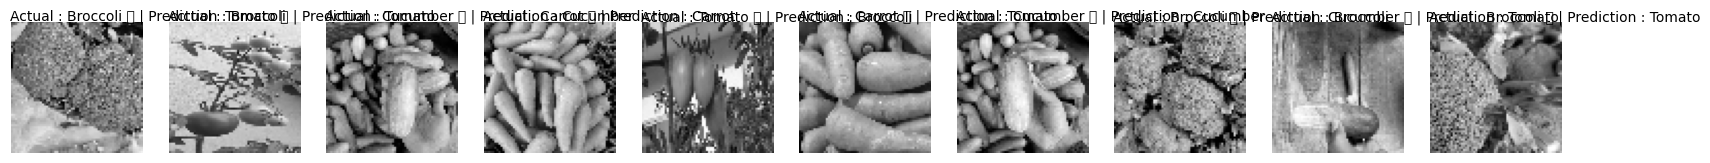

In [26]:
# yg hrusnya dilakukan di quiz, show gambar nya gitu
plt.figure(figsize=(20, 4))

# 10 gambar dalam 1 row
for i in range(10):
  plt.subplot(1, 10, i+1)
  plt.imshow(x_test[i], cmap="gray")
  plt.text(-1, -1, f"Actual : {CLASS_LIST[np.argmax(y_test[i])]} \t | Prediction : {CLASS_LIST[np.argmax(prediction_result[i])]}")
  plt.axis(False)

plt.show()

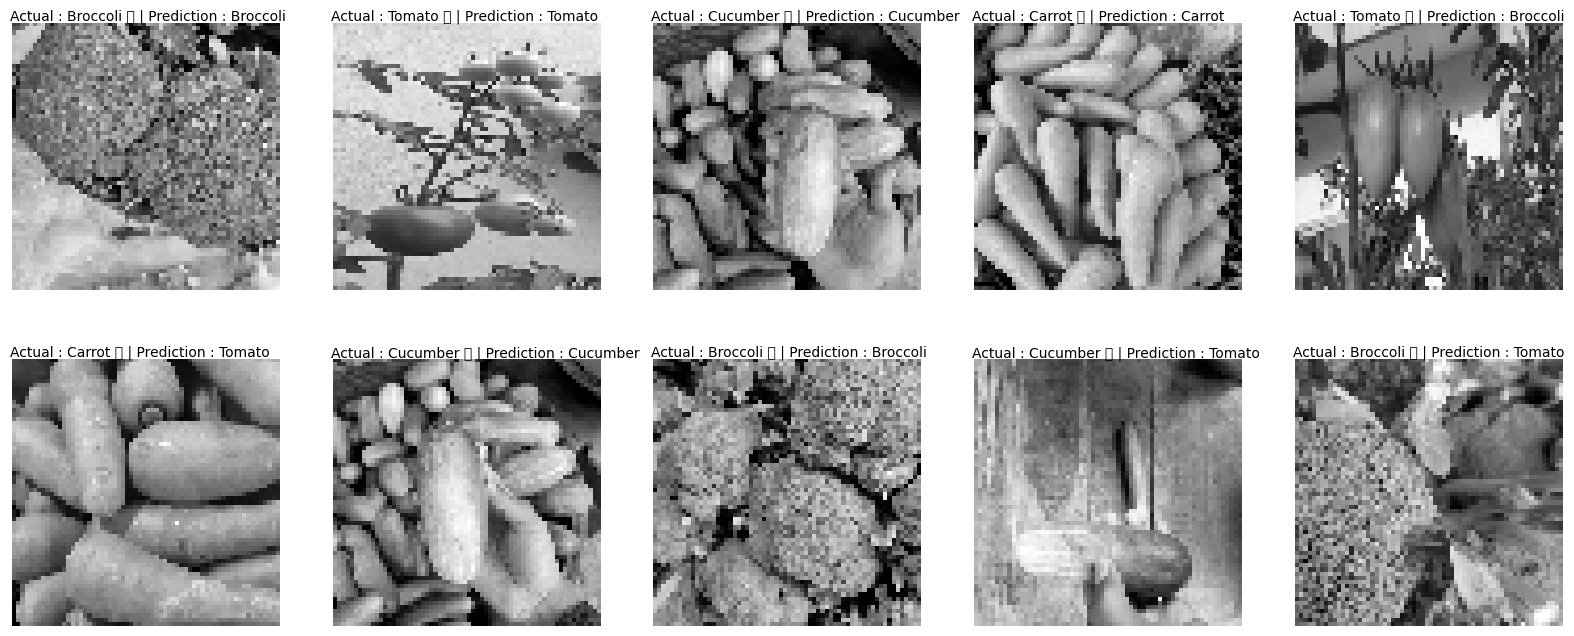

In [33]:
# Pake cara ini buat quiz TM1 nanti ya
# 10 gambar dalam 1 row
plt.figure(figsize=(20, 8))

for i in range(5):
  plt.subplot(2, 5, i+1)
  plt.imshow(x_test[i], cmap="gray")
  plt.text(-1, -1, f"Actual : {CLASS_LIST[np.argmax(y_test[i])]} \t | Prediction : {CLASS_LIST[np.argmax(prediction_result[i])]}")
  plt.axis(False)

  plt.subplot(2, 5, i+6)
  plt.imshow(x_test[i+5], cmap="gray")
  plt.text(-1, -1, f"Actual : {CLASS_LIST[np.argmax(y_test[i+5])]} \t | Prediction : {CLASS_LIST[np.argmax(prediction_result[i+5])]}")
  plt.axis(False)

plt.show()

## MODEL PLOT

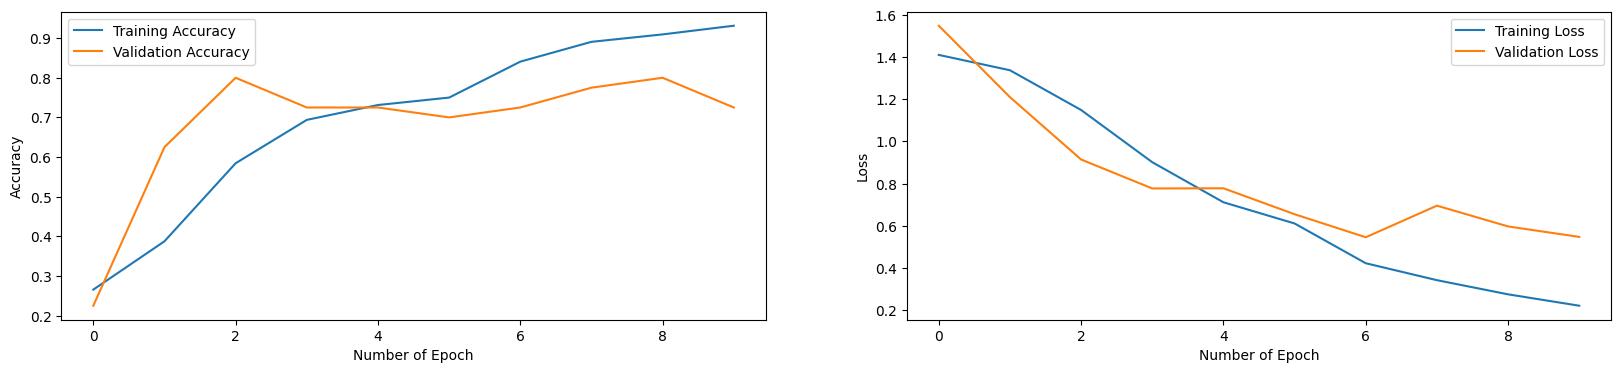

In [35]:
plt.figure(figsize=(20,4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.legend()
plt.xlabel("Number of Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label = "Training Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.legend()
plt.xlabel("Number of Epoch")
plt.ylabel("Loss")


plt.show()
